# DSCI 552 Homework 5

**Name:** Jingyu Zhang
**GitHub Username:** jingyuz9-wq
**USC ID:** 5744431585

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

SEED = 552
pd.set_option("display.max_rows", 200)

## 1. Decision Trees as Interpretable Models

### (a) Load the Acute Inflammations data

The file is UTF-16 encoded, tab-separated, and uses a comma as the decimal separator for temperature.

In [2]:
diag_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
             "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
diag = pd.read_csv("../data/acute_inflammations/diagnosis.data", encoding="utf-16",
                   sep="\t", header=None, names=diag_cols, decimal=",")
for c in diag_cols[1:]:
    diag[c] = (diag[c].str.strip() == "yes").astype(int)
print(diag.shape)
diag.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Decision tree on the whole data set

There are two binary labels (bladder inflammation, nephritis). I use the **label powerset** method: each combination of the two labels becomes one class, giving a 4-class problem. This is the more natural choice here because the two diseases co-occur and share symptoms; label powerset keeps that joint structure in one tree, whereas binary relevance would fit two independent trees and ignore the label dependence. With only two labels the powerset has just 4 classes, so the usual drawback (class explosion) is not an issue.

B=yes, N=no     40
B=no, N=yes     31
B=no, N=no      30
B=yes, N=yes    19
Name: count, dtype: int64
depth: 4  leaves: 6  training accuracy: 1.0


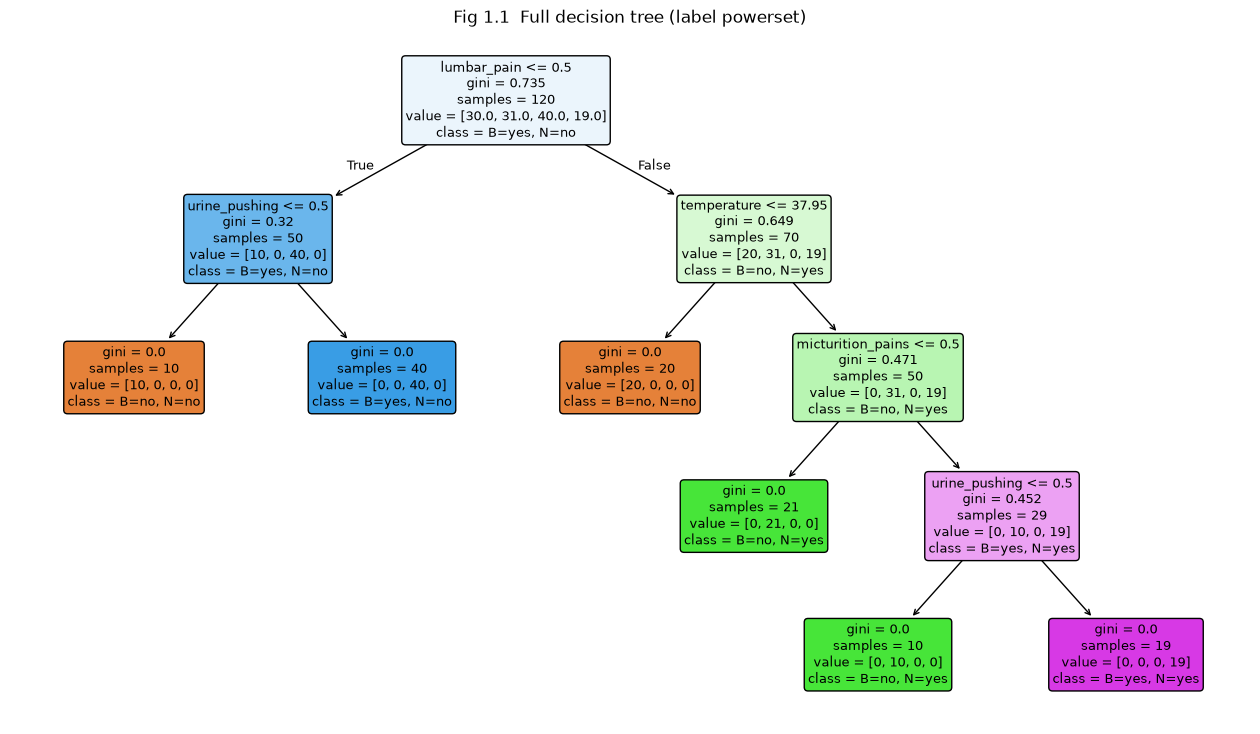

In [3]:
X1 = diag.iloc[:, :6]
y_bladder, y_neph = diag["bladder_inflammation"], diag["nephritis"]
y1 = ("B=" + y_bladder.map({1: "yes", 0: "no"}) + ", N=" + y_neph.map({1: "yes", 0: "no"}))
print(y1.value_counts())

tree_full = DecisionTreeClassifier(random_state=SEED).fit(X1, y1)
print("depth:", tree_full.get_depth(), " leaves:", tree_full.get_n_leaves(),
      " training accuracy:", tree_full.score(X1, y1))

fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(tree_full, feature_names=X1.columns, class_names=tree_full.classes_,
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Fig 1.1  Full decision tree (label powerset)")
plt.show()

### (c) IF-THEN rules

Rules are extracted by walking every root-to-leaf path (adapted from the KDnuggets article).

In [4]:
def tree_to_rules(clf, feature_names):
    t = clf.tree_
    names = [feature_names[i] if i != _tree.TREE_UNDEFINED else None for i in t.feature]
    rules = []

    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = names[node], t.threshold[node]
            recurse(t.children_left[node], conds + [f"{name} <= {thr:.2f}"])
            recurse(t.children_right[node], conds + [f"{name} > {thr:.2f}"])
        else:
            counts = t.value[node][0]
            label = clf.classes_[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            rules.append((conds, label, n))

    recurse(0, [])
    return rules


def print_rules(clf, feature_names):
    for i, (conds, label, n) in enumerate(tree_to_rules(clf, list(feature_names)), 1):
        cond = " AND ".join(conds) if conds else "TRUE"
        print(f"Rule {i}: IF {cond} THEN [{label}]  (n={n})")


print_rules(tree_full, X1.columns)

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN [B=no, N=no]  (n=10)
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN [B=yes, N=no]  (n=40)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN [B=no, N=no]  (n=20)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN [B=no, N=yes]  (n=21)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN [B=no, N=yes]  (n=10)
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN [B=yes, N=yes]  (n=19)


Since all symptoms are 0/1, `x <= 0.50` means *no* and `x > 0.50` means *yes*.

### (d) Cost-complexity pruning

I compute the pruning path on the full data, evaluate each $\alpha$ with 5-fold stratified CV, and keep the **largest** $\alpha$ whose CV accuracy equals the best CV accuracy, i.e. the smallest tree that does not lose accuracy.

In [5]:
path = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X1, y1)
alphas = path.ccp_alphas[:-1]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for a in alphas:
    clf = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    cv_acc = cross_val_score(clf, X1, y1, cv=skf).mean()
    clf.fit(X1, y1)
    rows.append((a, clf.get_n_leaves(), clf.get_depth(), clf.score(X1, y1), cv_acc))
prune_df = pd.DataFrame(rows, columns=["ccp_alpha", "leaves", "depth", "train_acc", "cv_acc"])
prune_df

,ccp_alpha,leaves,depth,train_acc,cv_acc
0,0.000000,6,4,1.000000,0.991667
1,0.098167,4,2,0.841667,0.858333
2,0.133333,3,2,0.758333,0.766667
3,0.182000,2,1,0.591667,0.675000


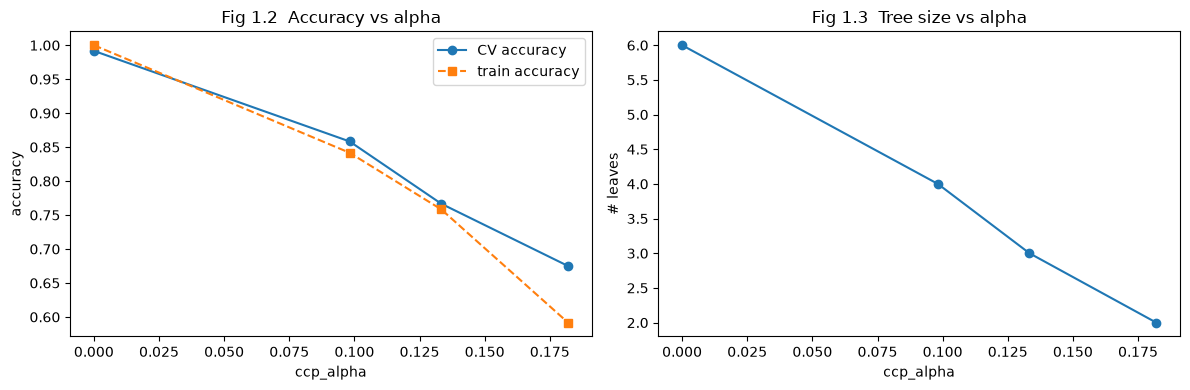

chosen alpha = 0.0000, leaves = 6, depth = 4, train acc = 1.000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(prune_df.ccp_alpha, prune_df.cv_acc, "o-", label="CV accuracy")
axes[0].plot(prune_df.ccp_alpha, prune_df.train_acc, "s--", label="train accuracy")
axes[0].set(xlabel="ccp_alpha", ylabel="accuracy", title="Fig 1.2  Accuracy vs alpha")
axes[0].legend()
axes[1].plot(prune_df.ccp_alpha, prune_df.leaves, "o-")
axes[1].set(xlabel="ccp_alpha", ylabel="# leaves", title="Fig 1.3  Tree size vs alpha")
plt.tight_layout()
plt.show()

best_alpha = prune_df.loc[prune_df.cv_acc == prune_df.cv_acc.max(), "ccp_alpha"].max()
tree_pruned = DecisionTreeClassifier(random_state=SEED, ccp_alpha=best_alpha).fit(X1, y1)
print(f"chosen alpha = {best_alpha:.4f}, leaves = {tree_pruned.get_n_leaves()}, "
      f"depth = {tree_pruned.get_depth()}, train acc = {tree_pruned.score(X1, y1):.3f}")

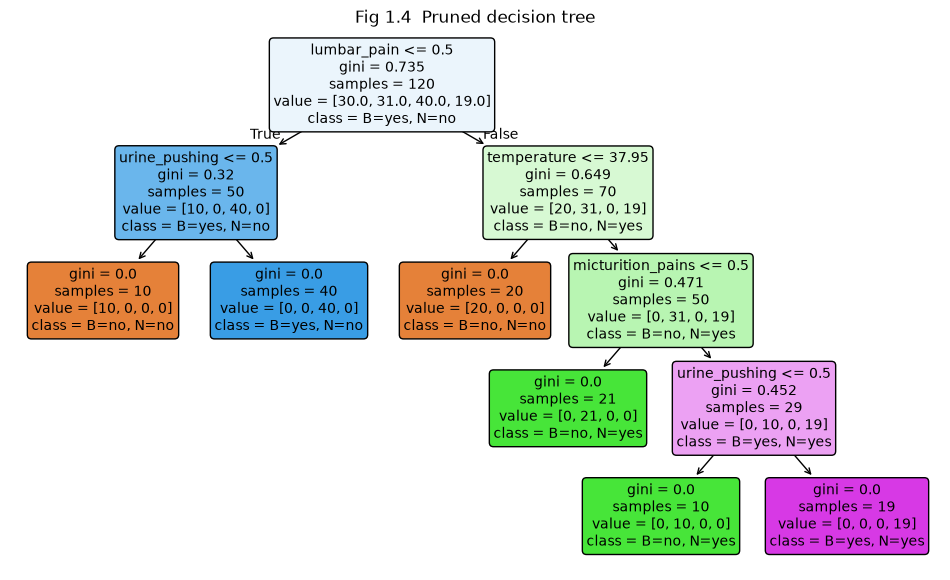

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN [B=no, N=no]  (n=10)
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN [B=yes, N=no]  (n=40)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN [B=no, N=no]  (n=20)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN [B=no, N=yes]  (n=21)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN [B=no, N=yes]  (n=10)
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN [B=yes, N=yes]  (n=19)


In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
plot_tree(tree_pruned, feature_names=X1.columns, class_names=tree_pruned.classes_,
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title("Fig 1.4  Pruned decision tree")
plt.show()

print_rules(tree_pruned, X1.columns)

**Answer (d):** The pruning path only has four candidate subtrees (6, 4, 3, 2 leaves). Every cut below the full tree loses a lot of accuracy (CV accuracy drops from 0.99 to 0.86 or lower), so cost-complexity pruning selects $\alpha = 0$: the 6-leaf, depth-4 tree is already the minimal tree that classifies the data correctly. The data were generated from expert rules, so this is expected.

The rule set can still be made easier to read. Rules 4 and 5 lead to the same class and can be merged, which gives the following five rules:

1. IF no lumbar pain AND no urine pushing → **healthy** (neither disease)
2. IF no lumbar pain AND urine pushing → **bladder inflammation only**
3. IF lumbar pain AND temperature ≤ 37.95 → **healthy**
4. IF lumbar pain AND temperature > 37.95 AND NOT (micturition pains AND urine pushing) → **nephritis only**
5. IF lumbar pain AND temperature > 37.95 AND micturition pains AND urine pushing → **both diseases**

This matches the domain description: nephritis needs lumbar pain plus fever, and bladder inflammation is driven by the urinary symptoms (urine pushing, micturition pains).

## 2. The LASSO and Boosting for Regression

### (a) Load the Communities and Crime data

In [8]:
attr_names = [line.split()[1] for line in open("../data/communities_crime/communities.names")
              if line.startswith("@attribute")]
crime = pd.read_csv("../data/communities_crime/communities.data", header=None,
                    names=attr_names, na_values="?")
print(crime.shape)

non_predictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
crime = crime.drop(columns=non_predictive)

train_df, test_df = crime.iloc[:1495], crime.iloc[1495:]
X_train_raw, y_train = train_df.drop(columns=target), train_df[target]
X_test_raw, y_test = test_df.drop(columns=target), test_df[target]
print("train:", X_train_raw.shape, " test:", X_test_raw.shape)

(1994, 128)
train: (1495, 122)  test: (499, 122)


### (b) Missing values

The five non-predictive columns (`state`, `county`, `community`, `communityname`, `fold`) were dropped above. For the remaining features I use **median imputation**, with medians computed on the training set only and then applied to both sets so that no test information leaks into training.

In [9]:
missing = X_train_raw.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

imputer = SimpleImputer(strategy="median").fit(X_train_raw)
X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)
print("remaining NaNs:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

PctPolicBlack           1256
PctPolicHisp            1256
LemasGangUnitDeploy     1256
LemasPctPolicOnPatr     1256
PolicOperBudg           1256
PolicCars               1256
PolicAveOTWorked        1256
NumKindsDrugsSeiz       1256
OfficAssgnDrugUnits     1256
PctPolicMinor           1256
PctPolicAsian           1256
PolicBudgPerPop         1256
LemasSwornFT            1256
PctPolicWhite           1256
RacialMatchCommPol      1256
PolicPerPop             1256
PolicReqPerOffic        1256
LemasTotReqPerPop       1256
LemasTotalReq           1256
LemasSwFTFieldPerPop    1256
LemasSwFTFieldOps       1256
LemasSwFTPerPop         1256
OtherPerCap                1
dtype: int64
remaining NaNs: 0 0


One feature (`OtherPerCap`) has a single missing value; the 22 LEMAS police features are missing for about 84% of communities, so after imputation they are close to constant.

### (c) Correlation matrix

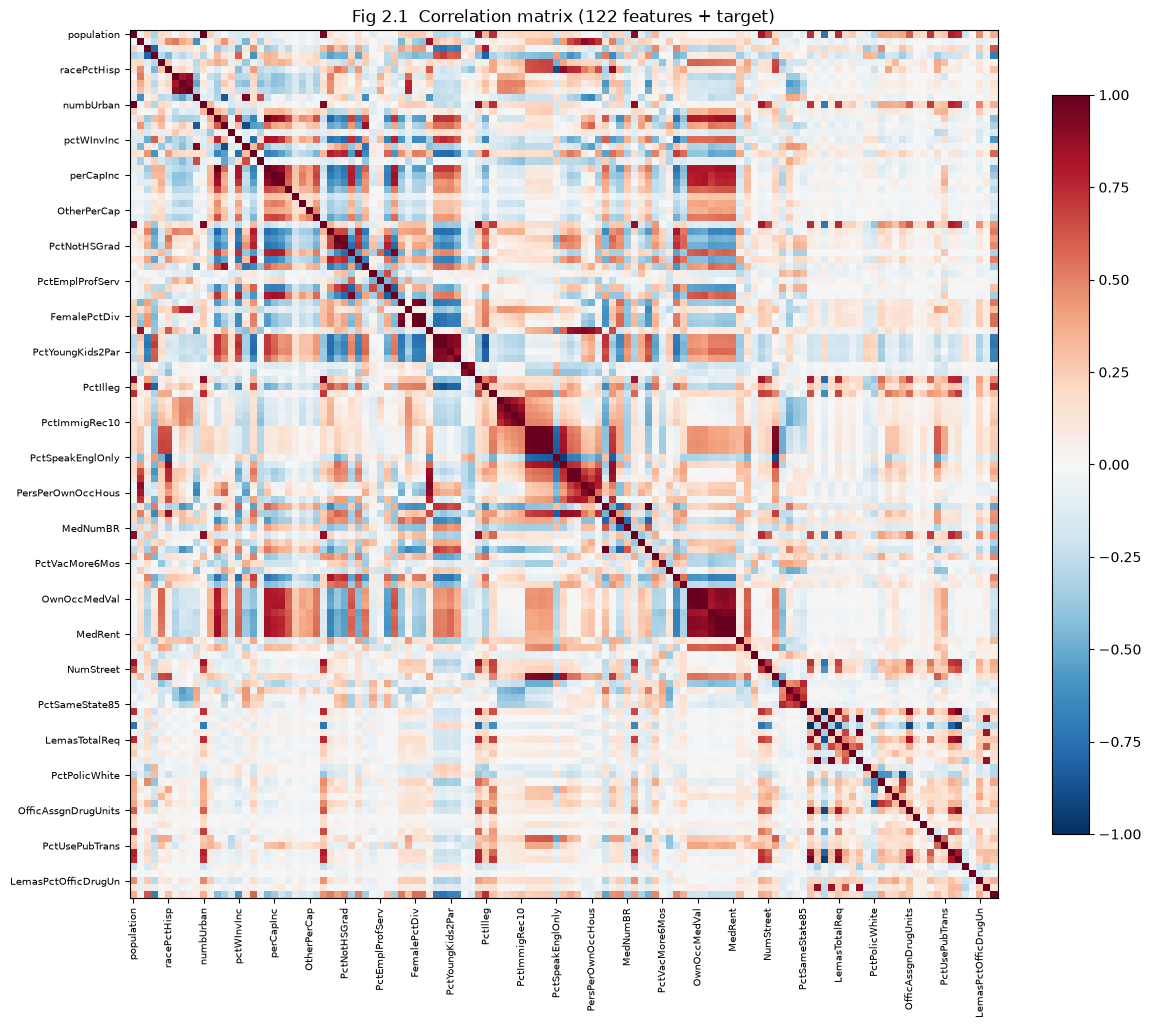

Top features by |corr| with target:
PctKids2Par         0.738424
PctIlleg            0.737957
PctFam2Par          0.706667
racePctWhite        0.684770
PctYoungKids2Par    0.666059
PctTeen2Par         0.661582
racepctblack        0.631264
pctWInvInc          0.576324
pctWPubAsst         0.574665
FemalePctDiv        0.556032
Name: ViolentCrimesPerPop, dtype: float64


In [10]:
X_all = pd.concat([X_train, X_test])
corr = pd.concat([X_all, crime[target]], axis=1).corr()

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(0, len(corr), 5))
ax.set_xticklabels(corr.columns[::5], rotation=90, fontsize=7)
ax.set_yticks(range(0, len(corr), 5))
ax.set_yticklabels(corr.columns[::5], fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Fig 2.1  Correlation matrix (122 features + target)")
plt.show()

print("Top features by |corr| with target:")
print(corr[target].drop(target).abs().sort_values(ascending=False).head(10))

### (d) Coefficient of variation $CV = s/m$

In [11]:
cv = (X_all.std() / X_all.mean()).sort_values(ascending=False)
cv.to_frame("CV")

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
LemasPctOfficDrugUn,2.555266
NumUnderPov,2.304970
population,2.203503
LemasSwornFT,2.080712
numbUrban,2.001744


### (e) Top $\lfloor\sqrt{128}\rfloor = 11$ features by CV

11 ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


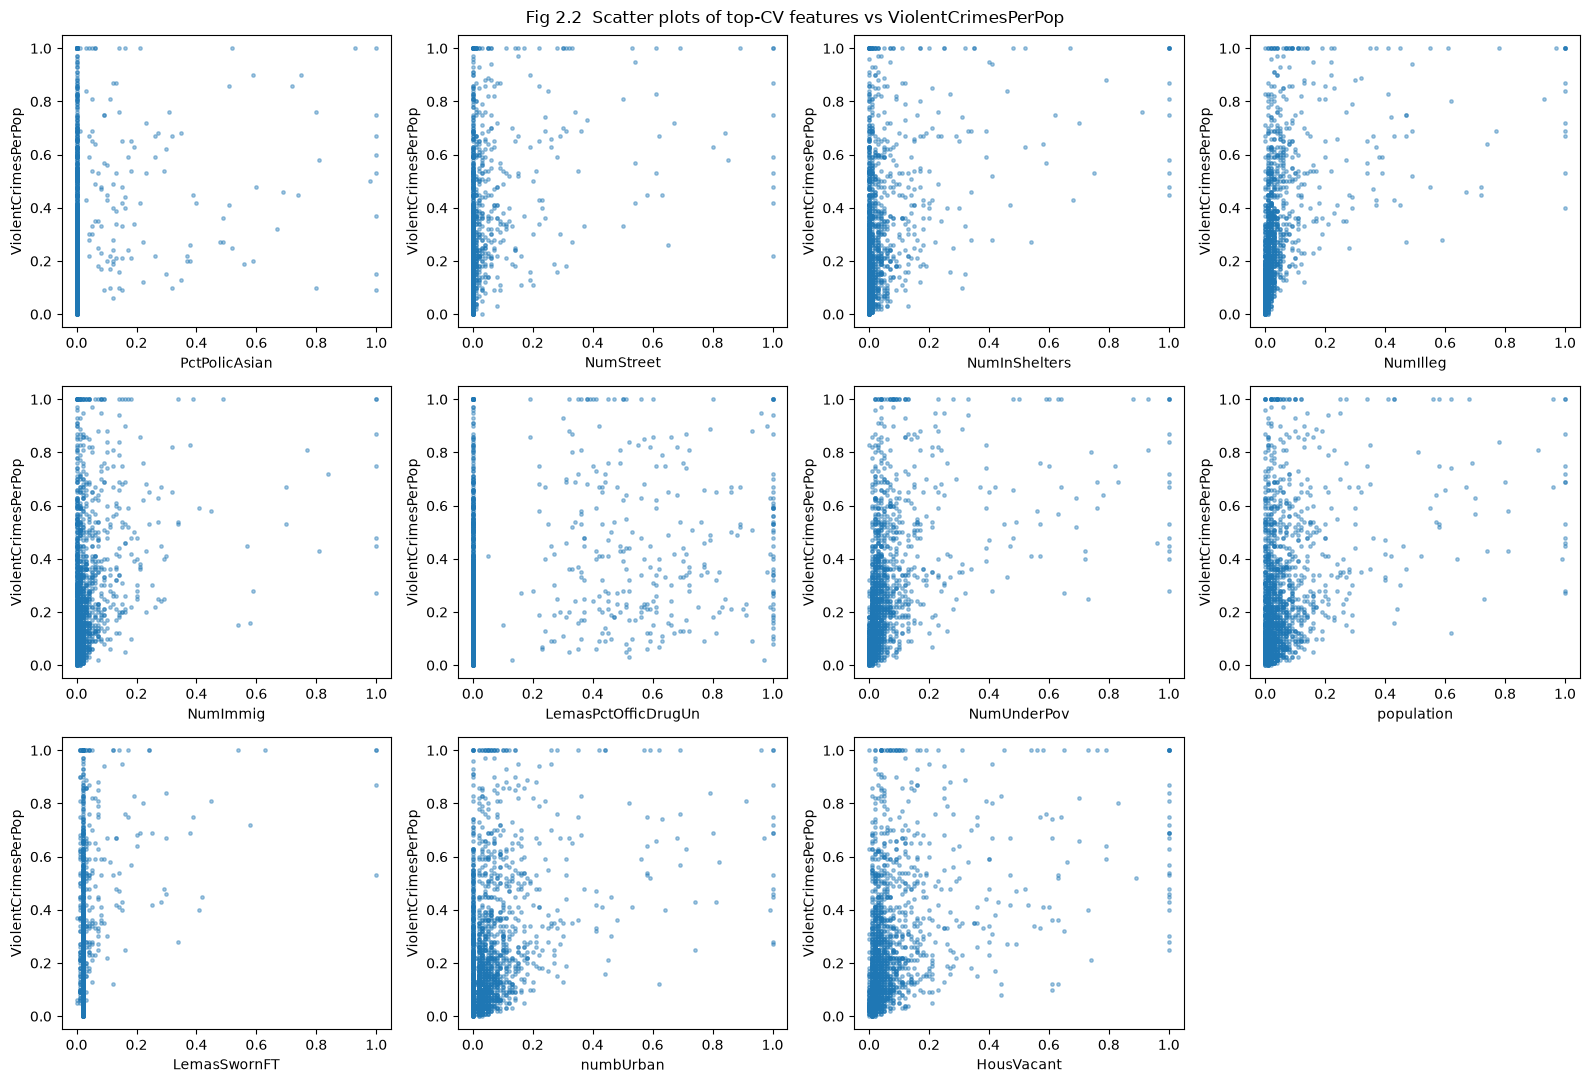

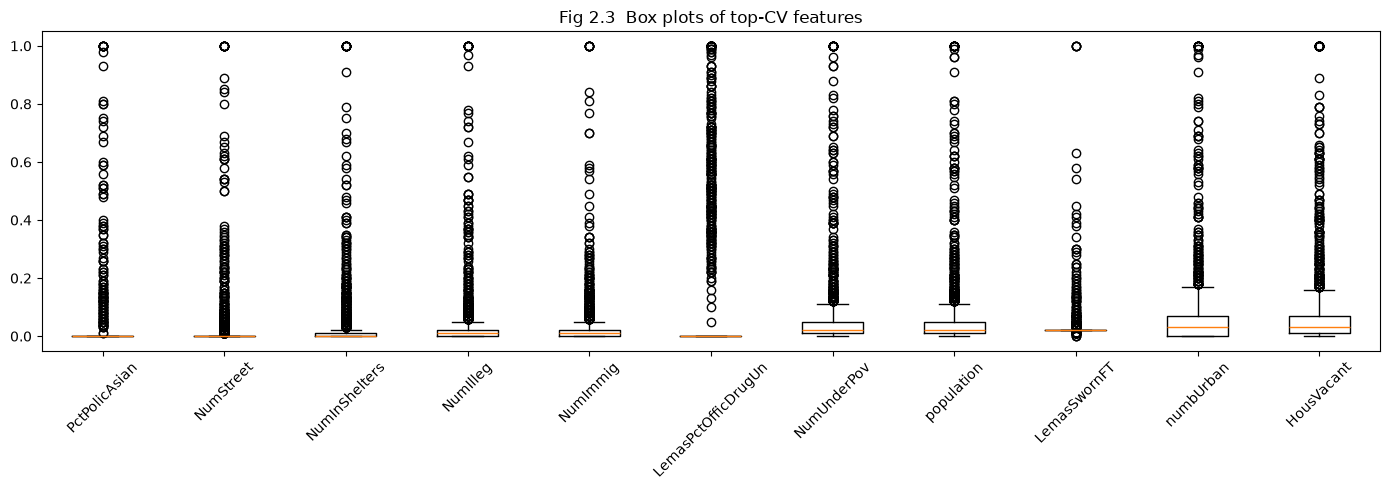

In [12]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv.index[:k].tolist()
print(k, top_cv)

y_all = crime[target]
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, top_cv):
    ax.scatter(X_all[f], y_all, s=6, alpha=0.4)
    ax.set(xlabel=f, ylabel=target)
axes.flat[-1].axis("off")
fig.suptitle("Fig 2.2  Scatter plots of top-CV features vs ViolentCrimesPerPop")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot([X_all[f] for f in top_cv], tick_labels=top_cv)
ax.tick_params(axis="x", rotation=45)
ax.set_title("Fig 2.3  Box plots of top-CV features")
plt.tight_layout()
plt.show()

**Answer (e):** No. The scatter plots do not support conclusions about significance. Most of the high-CV features are count variables (`NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `NumUnderPov`, `population`, `numbUrban`, `HousVacant`). Their high CV comes from a strongly right-skewed distribution, with most communities near 0 and a few large cities as outliers (see the box plots), not from a link to the response. Two of the selected features (`PctPolicAsian`, `LemasPctOfficDrugUn`) are LEMAS variables that are ~84% imputed, which also makes them look degenerate. In the scatter plots the points pile up near zero with a large vertical spread in `ViolentCrimesPerPop`, and at most you see a weak positive trend for some count features. A high CV says nothing about how strongly a feature relates to the response. Significance has to be judged with a fitted model (e.g. coefficient t-tests or LASSO selection) that accounts for the other features, and the many highly correlated predictors in Fig 2.1 make that especially important.

### (f) Linear model (least squares)

In [13]:
results = {}
ols = LinearRegression().fit(X_train, y_train)
results["OLS"] = mean_squared_error(y_test, ols.predict(X_test))
print(f"OLS test MSE: {results['OLS']:.5f}")

OLS test MSE: 0.01797


### (g) Ridge regression ($\lambda$ by 10-fold CV)

In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=SEED)
lambdas = np.logspace(-3, 3, 100)

ridge = RidgeCV(alphas=lambdas, cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["Ridge"] = mean_squared_error(y_test, ridge.predict(X_test))
print(f"best lambda = {ridge.alpha_:.4f}, ridge test MSE: {results['Ridge']:.5f}")

best lambda = 2.1544, ridge test MSE: 0.01753


### (h) LASSO ($\lambda$ by 10-fold CV)

In [15]:
lasso = LassoCV(cv=kf, alphas=100, max_iter=50000, random_state=SEED).fit(X_train, y_train)
results["LASSO"] = mean_squared_error(y_test, lasso.predict(X_test))
sel = X_train.columns[lasso.coef_ != 0]
print(f"best lambda = {lasso.alpha_:.6f}, LASSO test MSE: {results['LASSO']:.5f}")
print(f"{len(sel)} variables selected:")
pd.Series(lasso.coef_[lasso.coef_ != 0], index=sel).sort_values(key=abs, ascending=False)

best lambda = 0.000082, LASSO test MSE: 0.01769
79 variables selected:


agePct12t29             -0.320267
racepctblack             0.269764
PctPersDenseHous         0.238198
PctKids2Par             -0.201387
MedRent                  0.182959
PctEmploy                0.175529
MalePctNevMarr           0.172282
RentLowQ                -0.171386
NumStreet                0.163838
PctPopUnderPov          -0.160078
MalePctDivorce           0.146738
PctWorkMom              -0.141611
HousVacant               0.131075
pctWInvInc              -0.127116
FemalePctDiv            -0.119467
PersPerOccupHous         0.117585
NumImmig                -0.117548
pctWRetire              -0.111392
PctLargHouseOccup       -0.111147
NumIlleg                -0.109043
PolicReqPerOffic         0.104432
pctWWage                -0.100731
PctNotSpeakEnglWell     -0.095520
PctIlleg                 0.093214
MedRentPctHousInc        0.091301
agePct12t21              0.083699
whitePerCap             -0.082532
LemasSwFTFieldPerPop     0.081530
MedOwnCostPctIncNoMtg   -0.081178
NumInShelters 

In [16]:
lasso_std = make_pipeline(StandardScaler(),
                          LassoCV(cv=kf, alphas=100, max_iter=50000, random_state=SEED))
lasso_std.fit(X_train, y_train)
lcv = lasso_std[-1]
results["LASSO (standardized)"] = mean_squared_error(y_test, lasso_std.predict(X_test))
sel_std = X_train.columns[lcv.coef_ != 0]
print(f"best lambda = {lcv.alpha_:.6f}, standardized LASSO test MSE: {results['LASSO (standardized)']:.5f}")
print(f"{len(sel_std)} variables selected:")
pd.Series(lcv.coef_[lcv.coef_ != 0], index=sel_std).sort_values(key=abs, ascending=False)

best lambda = 0.000619, standardized LASSO test MSE: 0.01773
76 variables selected:


racepctblack             0.068089
agePct12t29             -0.043767
PctPersDenseHous         0.043656
PctKids2Par             -0.040606
RentLowQ                -0.031110
MedRent                  0.030892
PctPopUnderPov          -0.029672
PctEmploy                0.025497
MalePctNevMarr           0.025137
PctIlleg                 0.023830
PctWorkMom              -0.022487
pctWInvInc              -0.022312
MalePctDivorce           0.021556
pctWRetire              -0.017913
HousVacant               0.017591
NumStreet                0.017478
pctUrban                 0.017181
MedRentPctHousInc        0.015300
PctVacantBoarded         0.015123
FemalePctDiv            -0.015102
MedOwnCostPctIncNoMtg   -0.014679
pctWWage                -0.014531
PctNotSpeakEnglWell     -0.013538
agePct12t21              0.012709
PctLargHouseOccup       -0.012557
PctHousOccup            -0.011858
PctPersOwnOccup         -0.011676
PctHousLess3BR           0.011454
NumImmig                -0.011387
PctVacMore6Mos

In [17]:
print("selected in both:", len(set(sel) & set(sel_std)))
print("only raw:", sorted(set(sel) - set(sel_std)))
print("only standardized:", sorted(set(sel_std) - set(sel)))

selected in both: 75
only raw: ['PctBSorMore', 'PctWorkMomYoungKids', 'agePct65up', 'medFamInc']
only standardized: ['PctImmigRecent']


**Answer (h):** Both LASSO fits give almost the same test MSE (≈0.0177 raw vs ≈0.0177 standardized). Both are slightly better than OLS and close to ridge. The selected sets are also nearly identical: 79 variables on the raw features vs 76 on standardized features, with 75 in common. Standardizing makes little difference here because the features are already min–max normalized to [0, 1], so their scales are already comparable. The only effect is a rescaled $\lambda$ and coefficients, plus a few borderline variables swapping in or out. The strongest predictors are consistent across both fits: `racepctblack`, `agePct12t29`, `PctPersDenseHous`, `PctKids2Par`, `MedRent`, `RentLowQ`, `PctPopUnderPov`, `PctEmploy` and `MalePctNevMarr`.

### (i) Principal Components Regression ($M$ by 10-fold CV)

best M = 97, PCR test MSE: 0.01837


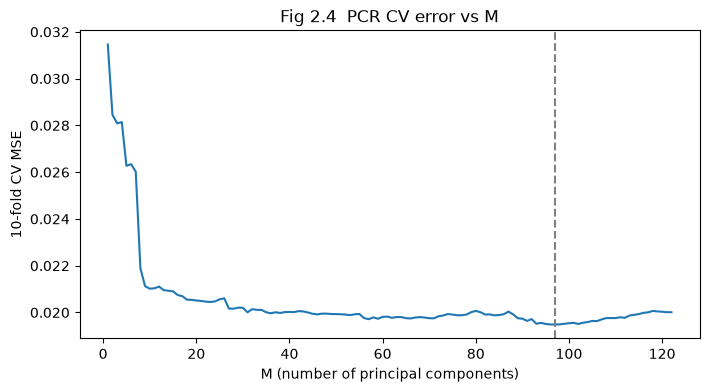

In [18]:
pcr = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())])
pcr_cv = GridSearchCV(pcr, {"pca__n_components": range(1, X_train.shape[1] + 1)},
                      cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
best_M = pcr_cv.best_params_["pca__n_components"]
results["PCR"] = mean_squared_error(y_test, pcr_cv.predict(X_test))
print(f"best M = {best_M}, PCR test MSE: {results['PCR']:.5f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, X_train.shape[1] + 1), -pcr_cv.cv_results_["mean_test_score"])
ax.axvline(best_M, ls="--", c="gray")
ax.set(xlabel="M (number of principal components)", ylabel="10-fold CV MSE",
       title="Fig 2.4  PCR CV error vs M")
plt.show()

### (j) L1-penalized gradient boosting tree (XGBoost)

`reg_alpha` is XGBoost's L1 penalty on the leaf weights. I fix a reasonably conservative booster (shallow trees, small learning rate, subsampling) and select $\alpha$ by 10-fold CV.

best alpha = 0.02154, XGBoost test MSE: 0.01600


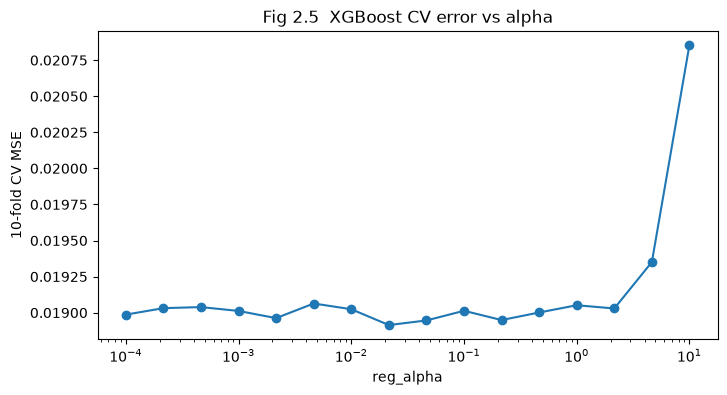

In [19]:
xgb = XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.5, random_state=SEED, n_jobs=-1)
xgb_cv = GridSearchCV(xgb, {"reg_alpha": np.logspace(-4, 1, 16)}, cv=kf,
                      scoring="neg_mean_squared_error").fit(X_train, y_train)
best_a = xgb_cv.best_params_["reg_alpha"]
results["XGBoost (L1)"] = mean_squared_error(y_test, xgb_cv.predict(X_test))
print(f"best alpha = {best_a:.4g}, XGBoost test MSE: {results['XGBoost (L1)']:.5f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(xgb_cv.param_grid["reg_alpha"], -xgb_cv.cv_results_["mean_test_score"], "o-")
ax.set(xlabel="reg_alpha", ylabel="10-fold CV MSE", title="Fig 2.5  XGBoost CV error vs alpha")
plt.show()

### Summary of test errors

In [20]:
pd.Series(results, name="test MSE").to_frame().sort_values("test MSE")

,test MSE
XGBoost (L1),0.016003
Ridge,0.017525
LASSO,0.017688
LASSO (standardized),0.017727
OLS,0.017966
PCR,0.018366


**Discussion:** All linear models land in a narrow band (MSE ≈ 0.0175–0.0184). Ridge and LASSO improve slightly over OLS by shrinking the many collinear coefficients. PCR needs a large number of components (M = 97) and does slightly worse than OLS on the test set, which suggests the response is not concentrated in the top principal components. The L1-penalized XGBoost model has the lowest test error (≈0.0160), because it can capture nonlinearities and interactions that the linear models miss.